# Figure A3: linear random features on Pile token statistics

Camera-ready version of the appendix figure `fig:pile-linear` (Appendix, *Experiments on Pile Token Statistics*). The first cells draw the figure from `matched_sweeps.npz` and reproduce the fitted exponents: sparse $\alpha_N=1.321$, $\alpha_D=1.259$, gap $+0.062$; dense $\alpha_N=1.242$, $\alpha_D=1.262$, gap $-0.020$. Nothing is recomputed.

Each sweep is compensated by its own design's model-size exponent, $(\ell/\ell_0)(z/z_0)^{\alpha_N}-1$ with $z=N$ or $D$, so the log-slope of the $D$-sweep is $\alpha_N-\alpha_D$. Printed size $5.5\times1.9$ in (`\textwidth`): tick labels 7 pt, axis labels 8 pt, titles 9 pt, legends 7 pt.

The cells under *Experiment* are the original experiment (`o200k_base` token counts over $1.48\times10^8$ Pile tokens in `cnt_raw.npy`). With `RELOAD = True` they load `matched_sweeps.npz` and print the exponents with bootstrap intervals; `RELOAD = False` recomputes the sweeps (one GPU, about 40 minutes).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.transforms as mtransforms

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt); the figure is drawn at its size on the page
FIG_W, FIG_H = 5.5, 1.9          # inches
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 7, 8, 9, 7

def style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=FS_LABEL, labelpad=1)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=1)
    ax.tick_params(which="both", labelsize=FS_TICK, pad=1.5)
    ax.tick_params(which="major", length=2.5)
    ax.tick_params(which="minor", length=1.5)

gmean = lambda Y: np.exp(np.log(Y).mean(0))                       # geometric mean over seeds
gse   = lambda Y: gmean(Y) * np.log(Y).std(0) / np.sqrt(Y.shape[0])
slope = lambda x, Y: -np.polyfit(np.log(np.asarray(x, float)), np.log(Y).mean(0), 1)[0]

sparse  alpha_N 1.321   alpha_D 1.259   gap +0.062
dense   alpha_N 1.242   alpha_D 1.262   gap -0.020


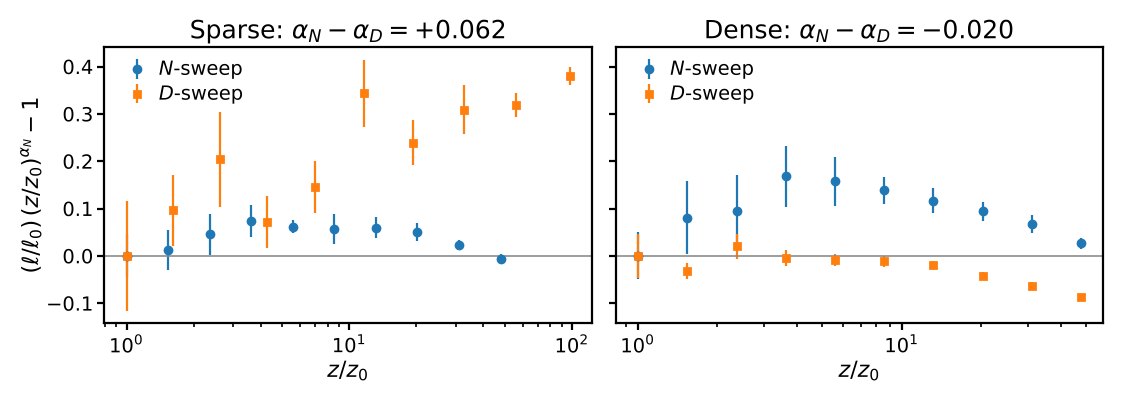

In [2]:
# FIGURE A3: each sweep compensated by its own design's alpha_N
m = np.load("matched_sweeps.npz")
x = {("sparse", "N"): m["N"], ("dense", "N"): m["N"], ("sparse", "D"): m["D_sparse"], ("dense", "D"): m["D_dense"]}
R = {("sparse", "N"): m["sN"], ("dense", "N"): m["dN"], ("sparse", "D"): m["sD"], ("dense", "D"): m["dD"]}

figA3, axs = plt.subplots(1, 2, figsize=(FIG_W, FIG_H), sharey=True, layout="constrained")
for ax, arm in zip(axs, ("sparse", "dense")):
    aN, aD = slope(x[(arm, "N")], R[(arm, "N")]), slope(x[(arm, "D")], R[(arm, "D")])
    print(f"{arm:7s} alpha_N {aN:.3f}   alpha_D {aD:.3f}   gap {aN - aD:+.3f}")
    for v, color, fmt, lab in (("N", "C0", "o", "$N$-sweep"), ("D", "C1", "s", "$D$-sweep")):
        zz, Y = x[(arm, v)].astype(float), R[(arm, v)]
        g, e = gmean(Y), gse(Y)
        ax.errorbar(zz / zz[0], (zz / zz[0])**aN * g / g[0] - 1, (zz / zz[0])**aN * e / g[0],
                    fmt=fmt, color=color, ms=2.5, elinewidth=0.8, capsize=0, label=lab)
    ax.axhline(0, color="0.55", lw=0.6)
    ax.set_xscale("log")
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    ax.set_title(rf"{arm.capitalize()}: $\alpha_N-\alpha_D={aN - aD:+.3f}$", fontsize=FS_TITLE, pad=3)
    style(ax, "$z/z_0$", r"$(\ell/\ell_0)\,(z/z_0)^{\alpha_N}-1$" if arm == "sparse" else "")
    ax.legend(loc="upper left", fontsize=FS_LEGEND, frameon=False, handletextpad=0.1,
              borderaxespad=0.3, labelspacing=0.25)
figA3.savefig("../figures/FigureA3.pdf")
figA3.savefig("../figures/FigureA3.png", dpi=300)
plt.show()

## Experiment

The original experiment notebook, kept as run. Its printed outputs are from that run; the figure above does not depend on running these cells.

# Model-size and data-size scaling under sparse activation (Pile token indicators)

Anonymous supplementary code.

**Claim under test.** Under sparse activation the learnable resource is
$\min(N, K(D))$, where $K(D)$ counts coordinates observed at least once in $D$
samples. $K$ grows sublinearly, so the data-side exponent is suppressed relative
to the model-side exponent:

| arm | $\beta = d\log K/d\log D$ over the window | prediction |
|---|---|---|
| sparse | $\beta < 1$, counted directly from the token stream | $\alpha_D < \alpha_N$ |
| dense control | $\beta = 1$ exactly, since $K(D) = D$ | $\alpha_D = \alpha_N$ |

$\beta$ is measured by counting. No exponent of the activation law is fitted.

**Design.** The sparse arm takes its activation pattern from tokenized text
(148M tokens of the Pile, `o200k_base`, 147,775 observed types). The dense
control is matched on the marginal variance spectrum, with every coordinate
active in every sample. Both arms use the same class of Gaussian random feature
map and the same min-norm solver, drawn independently.

**Matched windows.** Each arm's $D$-ladder is chosen so that its effective rank
sweeps the same range as the $N$-ladder. The local slope of the variance
spectrum is not constant, so $N$- and $D$-windows covering different ranks give
different exponents with no sparsity present at all; the dense control measures
that residual directly (Appendix A2).

**Scope.** The activation pattern and its frequency law are measured from text.
The amplitude assigned to each coordinate ($\alpha_2=0.3$) and the target
weights ($w_j$ i.i.d. standard normal) are specified.

**Runtime.** One GPU, roughly 40 minutes for the sweeps.

In [1]:
import numpy as np, time, os
import matplotlib.pyplot as plt

CFG = dict(tokenizer="o200k_base", dataset="monology/pile-uncopyrighted",
           char_budget=600_000_000, alpha2=0.3, rcond=1e-10, seed=20260731)
CKPT = "."

rng_for = lambda purpose, seed: np.random.default_rng([CFG["seed"], purpose, seed])

_ran = set()
def done(c): _ran.add(c)
def require(*cs):
    m = [c for c in cs if c not in _ran]
    if m: raise RuntimeError(f"run cell(s) {m} first")

try:
    import cupy as cp; xp, GPU = cp, True
except ImportError:
    xp, GPU = np, False
to_np = lambda a: np.asarray(a.get() if hasattr(a, "get") else a)
def free():
    if GPU: cp.get_default_memory_pool().free_all_blocks()

def checkpoint(name, **arr):
    global CKPT
    err = []
    for t in (CKPT, "."):
        try:
            os.makedirs(t, exist_ok=True); np.savez(f"{t}/{name}", **arr); CKPT = t; return
        except Exception as e:
            err.append(f"{t}: {e}")
    raise IOError(f"could not write {name} -- " + "; ".join(err))

print("gpu" if GPU else "cpu")
done(0)

gpu


## Data, spectrum, coverage

In [2]:
require(0)

def token_counts():
    import tiktoken
    from datasets import load_dataset
    enc = tiktoken.get_encoding(CFG["tokenizer"])
    cnt, buf, nch = np.zeros(enc.n_vocab + 5000, np.int64), [], 0
    for rec in load_dataset(CFG["dataset"], split="train", streaming=True):
        buf.append(rec["text"]); nch += len(rec["text"])
        if len(buf) == 500:
            ids = np.concatenate([np.asarray(e, np.int64) for e in enc.encode_ordinary_batch(buf)])
            bc = np.bincount(ids); cnt[:bc.size] += bc; buf = []
            if nch >= CFG["char_budget"]: break
    return cnt

DRIVE = "/content/drive/MyDrive/alphaN_ckpt"
if os.path.exists("cnt_raw.npy"):
    CKPT = "."                       # files shipped alongside the notebook
else:
    try:
        from google.colab import drive; drive.mount("/content/drive")
        CKPT = DRIVE
    except Exception:
        CKPT = "."
os.makedirs(CKPT, exist_ok=True)

if os.path.exists(f"{CKPT}/cnt_raw.npy"):
    cnt_raw = np.load(f"{CKPT}/cnt_raw.npy")
else:
    !pip install -q tiktoken
    cnt_raw = token_counts(); np.save(f"{CKPT}/cnt_raw.npy", cnt_raw)

c     = np.sort(cnt_raw.astype(np.float64))[::-1]; c = c[c > 0]
M     = c.size
n_tok = int(c.sum())
p     = c / c.sum()                          # activation probability, measured
rank  = np.arange(1, M + 1, dtype=np.float64)
amp   = rank ** (-(CFG["alpha2"] + 1) / 2)   # amplitude, specified
var   = p * amp ** 2                         # marginal variance spectrum, shared by both arms

def K_of(D):
    D = np.atleast_1d(np.asarray(D, float))
    return np.array([float((1 - np.exp(-d * p)).sum()) for d in D])

def D_for(K, lo=10.0, hi=None):
    g = np.logspace(np.log10(lo), np.log10(hi or 0.9 / p.min()), 3000)
    return float(g[np.argmin(np.abs(K_of(g) - K))])

print(f"{M:,} observed types, {n_tok:,} tokens")
Dg = np.logspace(1.5, 7, 80); beta_g = np.gradient(np.log(K_of(Dg)), np.log(Dg))
print(f"\n{'D':>10}{'K(D)':>10}{'K/D':>8}{'beta':>8}")
for d in (1e2, 1e3, 1e4, 1e5, 1e6):
    k = K_of(d)[0]
    print(f"{d:10,.0f}{k:10,.0f}{k/d:8.2f}{np.interp(np.log(d), np.log(Dg), beta_g):8.3f}")
done(1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
147,775 observed types, 148,282,604 tokens

         D      K(D)     K/D    beta
       100        87    0.87   0.911
     1,000       663    0.66   0.851
    10,000     4,281    0.43   0.759
   100,000    20,554    0.21   0.591
 1,000,000    62,230    0.06   0.364


## Estimators

For $L_0=1$ every sample activates one coordinate, so the design is determined by
the per-coordinate counts and the cost of a solve is independent of $D$. Gram
accumulation is in float64: float32 here costs four orders of accuracy.

In [3]:
require(0, 1)

def make_u(Nmax, seed, chunk=4096):
    g = np.random.default_rng(seed) if xp is np else cp.random.default_rng(seed)
    u = xp.empty((Nmax, M), dtype=xp.float32)
    for i in range(0, Nmax, chunk):
        k = min(chunk, Nmax - i)
        u[i:i+k] = g.standard_normal((k, M), dtype=xp.float32) / np.sqrt(Nmax)
    return u

def gram(u, N, counts, w, chunk=2048):
    assert N <= u.shape[0], f"N={N} exceeds u rows={u.shape[0]}"
    obs = np.flatnonzero(counts > 0)
    G = xp.zeros((N, N), xp.float64); b = xp.zeros(N, xp.float64)
    for i in range(0, obs.size, chunk):
        j  = obs[i:i+chunk]
        g  = np.sqrt(counts[j]) * amp[j]
        Bc = u[:N, xp.asarray(j)].astype(xp.float64) * xp.asarray(g)
        G += Bc @ Bc.T
        b += Bc @ xp.asarray(g * w[j])
    return G, b

def solve(G, b, cond_max=1e11):
    d = to_np(xp.diag(G))
    if d.max() / max(d.min(), np.finfo(float).tiny) < cond_max:
        try:
            L = xp.linalg.cholesky(G)
            return to_np(xp.linalg.solve(L.T, xp.linalg.solve(L, b)))
        except Exception:
            pass
    ev, V = xp.linalg.eigh(G)
    keep = ev > 1e-16 * ev[-1]; Vk = V[:, keep]
    return to_np(Vk @ ((Vk.T @ b) / ev[keep]))

def solve_svd(u, N, counts, w):
    """Min-norm via the SVD of an N x K matrix. Used when N > K(D), where the
    Gram is singular."""
    assert N <= u.shape[0], f"N={N} exceeds u rows={u.shape[0]}"
    obs = np.flatnonzero(counts > 0)
    g = np.sqrt(counts[obs]) * amp[obs]
    B = u[:N, xp.asarray(obs)].astype(xp.float64) * xp.asarray(g)
    U, Sv, Vt = xp.linalg.svd(B, full_matrices=False)
    keep = Sv > CFG["rcond"] * Sv[0]
    return to_np((U[:, keep] / Sv[keep]) @ (Vt[keep] @ xp.asarray(g * w[obs])))

def pop_loss(u, N, theta, target, chunk=4096):
    """Population loss in closed form. Evaluated in float64: float32 here is
    ~1e-7 and shows up as spurious solver disagreement."""
    th = xp.asarray(theta); what = np.empty(u.shape[1], np.float64)
    for i in range(0, u.shape[1], chunk):
        what[i:i+chunk] = to_np(u[:N, i:i+chunk].astype(xp.float64).T @ th)
    return float((var * (target - what) ** 2).sum())

def solve_dense(u, N, D, wd, seed, chunk=1024):
    """Dense control: every coordinate active, same marginal variance spectrum.
    Z is generated in row chunks rather than via an N x N Cholesky."""
    g  = np.random.default_rng(seed) if xp is np else cp.random.default_rng(seed)
    sd = xp.asarray(np.sqrt(var)); wdx = xp.asarray(wd)
    Z = xp.empty((D, N), xp.float64); y = xp.empty(D, xp.float64)
    for i in range(0, D, chunk):
        k = min(chunk, D - i)
        X = g.standard_normal((k, u.shape[1]), dtype=xp.float32).astype(xp.float64) * sd
        Z[i:i+k] = X @ u[:N].astype(xp.float64).T
        y[i:i+k] = X @ wdx
        del X
    if N <= D:
        th = solve(Z.T @ Z, Z.T @ y)
    else:
        ev, V = xp.linalg.eigh(Z @ Z.T)
        keep = ev > CFG["rcond"] * ev[-1]
        th = to_np(Z.T @ (V[:, keep] @ ((V[:, keep].T @ y) / ev[keep])))
    del Z, y; free()
    return th

done(2)

## Gate

Every estimator checked against a float64 SVD reference on the measured spectrum.
The float32 check is inverted deliberately: it asserts that float32 accumulation
*is* worse, so a silent upcast cannot pass unnoticed.

In [4]:
require(2)
_r = rng_for(99, 0); _N, _D = 90, 6000
_w = _r.standard_normal(M); _n = _r.multinomial(_D, p).astype(float)
_u = make_u(_N, [9, 9, 9]); _u64 = to_np(_u).astype(np.float64)
_L = lambda th, N: float((var * (_w - _u64[:N].T @ th) ** 2).sum())

def _ref(N):
    o = np.flatnonzero(_n > 0); g = np.sqrt(_n[o]) * amp[o]
    U, Sv, Vt = np.linalg.svd(_u64[:N, o] * g, full_matrices=False)
    k = Sv > CFG["rcond"] * Sv[0]
    return (U[:, k] / Sv[k]) @ (Vt[k] @ (g * _w[o]))

def _gram32(u, N, chunk=2048):
    obs = np.flatnonzero(_n > 0); G = xp.zeros((N, N), xp.float64); b = xp.zeros(N, xp.float64)
    for i in range(0, obs.size, chunk):
        j  = obs[i:i+chunk]; g = (np.sqrt(_n[j]) * amp[j]).astype(np.float32)
        Bc = u[:N, xp.asarray(j)] * xp.asarray(g)
        G += (Bc @ Bc.T).astype(xp.float64)
        b += (Bc @ xp.asarray((g * _w[j]).astype(np.float32))).astype(xp.float64)
    return G, b

_rel = lambda a, N: abs(a - _L(_ref(N), N)) / _L(_ref(N), N)
_z   = np.zeros(M)

assert abs(pop_loss(_u, 16, np.zeros(16), _w) - float((var * _w**2).sum())) < 1e-9
for _t in (25, 45, 90):
    assert _rel(pop_loss(_u, _t, solve(*gram(_u, _t, _n, _w)), _w), _t) < 1e-8
assert _rel(pop_loss(_u, 90, solve_svd(_u, 90, _n, _w), _w), 90) < 1e-8
assert _rel(pop_loss(_u, 90, solve(*_gram32(_u, 90)), _w), 90) > 1e-6      # float32 must be worse
assert pop_loss(_u, 45, solve(*gram(_u, 45, _n, _z)), _z) < 1e-30
assert pop_loss(_u, 45, solve_dense(_u, 45, 900, _z, [5, 5, 5]), _z) < 1e-30
assert pop_loss(_u, 90, solve_dense(_u, 90,  60, _z, [6, 6, 6]), _z) < 1e-30   # dual path
try:
    gram(_u, _N + 30, _n, _w); raise SystemExit("truncation guard absent")
except AssertionError:
    pass
_t1 = to_np(make_u(64, [1, 2, 3]))
assert abs(_t1.std() * 8 - 1) < 0.02 and abs(_t1.mean()) < 1e-3
assert np.array_equal(rng_for(1, 5).standard_normal(4), rng_for(1, 5).standard_normal(4))

del _u, _u64; free()
print("gate ok"); done(3)

gate ok


## Operating point

Every sweep spans the same effective-rank window. The sparse $D$-ladder is
derived from the coverage curve so that $K(D)$ sweeps that window; the dense
$D$-ladder is the window itself, since $K(D)=D$ there. Two guards: $K_{\max}/N$
bounds the min-norm leakage onto unobserved coordinates, and $D_{\max}/N$ keeps
the dense control away from its interpolation threshold at $D=N$.

In [5]:
require(1, 3)

R_LO, R_HI, NPTS = 90, 4300, 10          # effective-rank window
SEEDS_N, SEEDS_D_SPARSE, SEEDS_D_DENSE = 5, 30, 15

N_LADDER = np.unique(np.round(np.logspace(np.log10(R_LO), np.log10(R_HI), NPTS)).astype(int))
D_SPARSE = np.unique(np.array([int(round(D_for(k))) for k in N_LADDER]))
D_DENSE  = N_LADDER.copy()

N_FIXED    = 45_000                      # capacity for the D-sweeps
D_N_SPARSE = D_for(30 * R_HI, hi=n_tok)  # data for the sparse N-sweep
D_N_DENSE  = int(12 * R_HI)              # data for the dense N-sweep

K_sp = K_of(D_SPARSE.astype(float))
beta = np.gradient(np.log(K_sp), np.log(D_SPARSE.astype(float)))

print(f"rank window [{R_LO}, {R_HI}] = {np.log10(R_HI/R_LO):.2f} decades")
print(f"{'N':>7}{'D sparse':>10}{'K(D)':>8}{'beta':>7}{'D dense':>10}")
for i in range(len(N_LADDER)):
    print(f"{N_LADDER[i]:7d}{D_SPARSE[i]:10d}{K_sp[i]:8,.0f}{beta[i]:7.3f}{D_DENSE[i]:10d}")
print(f"\nmedian beta {np.median(beta):.3f} sparse, 1.000 dense")
print(f"N-sweeps at D = {D_N_SPARSE:,.0f} sparse (K = {K_of(D_N_SPARSE)[0]:,.0f}), "
      f"{D_N_DENSE:,} dense")
print(f"D-sweeps at N = {N_FIXED:,}: leakage K/N = {K_sp.max()/N_FIXED:.3f}, "
      f"threshold D/N = {D_DENSE.max()/N_FIXED:.3f}")

assert K_of(D_N_SPARSE)[0] > 5 * R_HI
assert D_N_DENSE > 5 * R_HI
assert K_sp.max() / N_FIXED < 0.15 and D_DENSE.max() / N_FIXED < 0.15
done(4)

rank window [90, 4300] = 1.68 decades
      N  D sparse    K(D)   beta   D dense
     90       103      90  0.903        90
    138       166     138  0.897       138
    213       271     213  0.885       213
    327       441     327  0.874       327
    502       721     501  0.860       502
    771      1193     771  0.846       771
   1185      1995   1,186  0.829      1185
   1821      3373   1,823  0.809      1821
   2798      5765   2,796  0.786      2798
   4300     10073   4,305  0.773      4300

median beta 0.853 sparse, 1.000 dense
N-sweeps at D = 32,802,900 sparse (K = 129,017), 51,600 dense
D-sweeps at N = 45,000: leakage K/N = 0.096, threshold D/N = 0.096


## Sweeps

Four sweeps. The $N$-sweeps hold data fixed and vary capacity; the $D$-sweeps
hold capacity fixed and vary data. The sparse solve costs the same at every $D$
because it depends on the data only through the per-coordinate counts.

`RELOAD = False` recomputes from scratch, about 40 minutes on one GPU.

In [6]:
require(2, 4)
RELOAD = True                     # False recomputes from scratch (~40 min on one GPU)

if RELOAD and os.path.exists(f"{CKPT}/matched_sweeps.npz"):
    _z = np.load(f"{CKPT}/matched_sweeps.npz")
    R = {("sparse","N"): _z["sN"], ("dense","N"): _z["dN"],
         ("sparse","D"): _z["sD"], ("dense","D"): _z["dD"]}
    assert np.array_equal(_z["N"], N_LADDER) and np.array_equal(_z["D_sparse"], D_SPARSE), \
        "checkpoint ladders differ from cell 9 -- set RELOAD = False"
    print("loaded " + "  ".join(f"{a}-{b} {R[(a,b)].shape[0]} seeds"
                                for a in ("sparse","dense") for b in ("N","D")))
else:
    R, t0 = {}, time.time()
    for arm in ("sparse", "dense"):                       # capacity branch
        rows = []
        for s in range(SEEDS_N):
            u = make_u(int(N_LADDER.max()), [CFG["seed"], 20 + (arm == "dense"), s])
            w = rng_for(22 + (arm == "dense"), s).standard_normal(M)
            if arm == "sparse":
                n = rng_for(24, s).multinomial(int(D_N_SPARSE), p).astype(np.float64)
            row = []
            for N in N_LADDER:
                if arm == "sparse":
                    th = solve(*gram(u, int(N), n, w)); free()
                else:
                    th = solve_dense(u, int(N), int(D_N_DENSE), w,
                                     [CFG["seed"], 26, s*100 + int(N)])
                row.append(pop_loss(u, int(N), th, w))
            del u; free(); rows.append(row)
        R[(arm, "N")] = np.array(rows)
        print(f"N-sweep {arm} done  [{time.time()-t0:.0f}s]", flush=True)

    for arm, nseed in (("sparse", SEEDS_D_SPARSE), ("dense", SEEDS_D_DENSE)):
        lad = D_SPARSE if arm == "sparse" else D_DENSE    # data branch
        rows = []
        for s in range(nseed):
            u = make_u(N_FIXED, [CFG["seed"], 30 + (arm == "dense"), s])
            w = rng_for(32 + (arm == "dense"), s).standard_normal(M)
            row = []
            for D in lad:
                if arm == "sparse":
                    n = rng_for(34, s*1000 + int(D)).multinomial(int(D), p).astype(np.float64)
                    th = solve_svd(u, N_FIXED, n, w); free()
                else:
                    th = solve_dense(u, N_FIXED, int(D), w,
                                     [CFG["seed"], 36, s*1000 + int(D)])
                row.append(pop_loss(u, N_FIXED, th, w))
            del u; free(); rows.append(row)
            if (s + 1) % 5 == 0:
                print(f"  {arm} D-sweep {s+1}/{nseed}  [{time.time()-t0:.0f}s]", flush=True)
        R[(arm, "D")] = np.array(rows)

    checkpoint("matched_sweeps.npz", N=N_LADDER, D_sparse=D_SPARSE, D_dense=D_DENSE,
               K_sp=K_sp, sN=R[("sparse","N")], dN=R[("dense","N")],
               sD=R[("sparse","D")], dD=R[("dense","D")])
    print(f"done [{time.time()-t0:.0f}s]")
done(5)

loaded sparse-N 5 seeds  sparse-D 30 seeds  dense-N 5 seeds  dense-D 15 seeds


## Exponents

In [7]:
require(5)

gmean = lambda Y: np.exp(np.log(Y).mean(0))
gse   = lambda Y: gmean(Y) * np.log(Y).std(0) / np.sqrt(Y.shape[0])

def slope(x, Y, nboot=4000, seed=0):
    """Exponent of L ~ x^-alpha. Geometric mean over seeds, CI bootstrapped over seeds."""
    lx, lY, n = np.log(np.asarray(x, float)), np.log(Y), Y.shape[0]
    g = np.random.default_rng(seed)
    boot = np.array([-np.polyfit(lx, lY[g.integers(0, n, n)].mean(0), 1)[0] for _ in range(nboot)])
    return -np.polyfit(lx, lY.mean(0), 1)[0], boot

xN = {a: N_LADDER.astype(float) for a in ("sparse", "dense")}
xD = {"sparse": D_SPARSE.astype(float), "dense": D_DENSE.astype(float)}
aN = {a: slope(xN[a], R[(a, "N")]) for a in ("sparse", "dense")}
aD = {a: slope(xD[a], R[(a, "D")]) for a in ("sparse", "dense")}
ci = lambda b: f"[{np.percentile(b, 2.5):+.3f}, {np.percentile(b, 97.5):+.3f}]"

print(f"{'':7}{'alpha_N':>21}{'alpha_D':>21}{'gap':>21}{'P>0':>7}")
for a in ("sparse", "dense"):
    (n, bn), (d, bd) = aN[a], aD[a]
    print(f"{a:7}{n:7.3f} {ci(bn)}{d:7.3f} {ci(bd)}{n-d:7.3f} {ci(bn-bd)}{(bn-bd>0).mean():7.3f}")

dd = (aN["sparse"][1] - aD["sparse"][1]) - (aN["dense"][1] - aD["dense"][1])
pt = (aN["sparse"][0] - aD["sparse"][0]) - (aN["dense"][0] - aD["dense"][0])
print(f"\nsparse gap - dense gap   {pt:+.3f} {ci(dd)}   P>0 {(dd > 0).mean():.3f}")
print(f"alpha_N / alpha_D        {aN['sparse'][0]/aD['sparse'][0]:.3f} sparse   "
      f"{aN['dense'][0]/aD['dense'][0]:.3f} dense (1.000 expected)")
print(f"beta, counted            {np.median(beta):.3f} sparse   1.000 dense")
print(f"seeds                    N {R[('sparse','N')].shape[0]}   "
      f"D {R[('sparse','D')].shape[0]} sparse, {R[('dense','D')].shape[0]} dense")
done(6)

                     alpha_N              alpha_D                  gap    P>0
sparse   1.321 [+1.301, +1.341]  1.259 [+1.227, +1.294]  0.062 [+0.021, +0.101]  0.998
dense    1.242 [+1.206, +1.281]  1.262 [+1.247, +1.279] -0.020 [-0.060, +0.020]  0.174

sparse gap - dense gap   +0.082 [+0.026, +0.133]   P>0 0.998
alpha_N / alpha_D        1.049 sparse   0.984 dense (1.000 expected)
beta, counted            0.853 sparse   1.000 dense
seeds                    N 5   D 30 sparse, 15 dense


## Figure

Loss against each resource, with the fitted exponent. The two arms share the
same variance spectrum, the same feature-map class and the same solver; they
differ only in whether the variance arrives through rare activations.


Figure 1.  Loss against each resource; each sweep fitted independently.



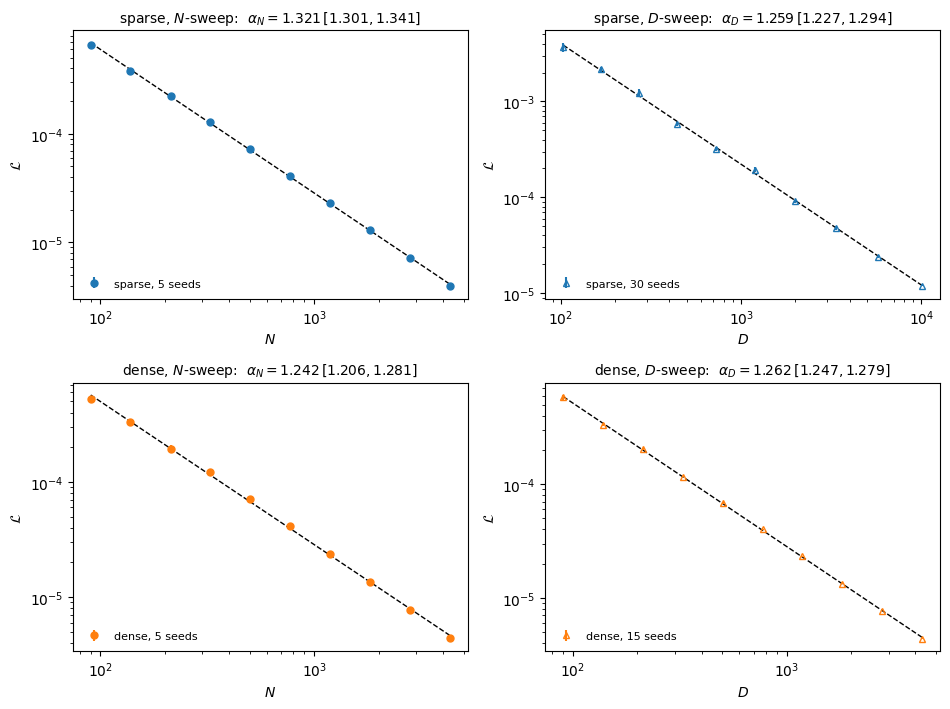



Figure 2.  Each arm compensated by its own model-size exponent.
Delta = 0 means the sweep follows the same power law as that arm's N-sweep;
the residual slope of the D-sweep is exactly alpha_N - alpha_D.



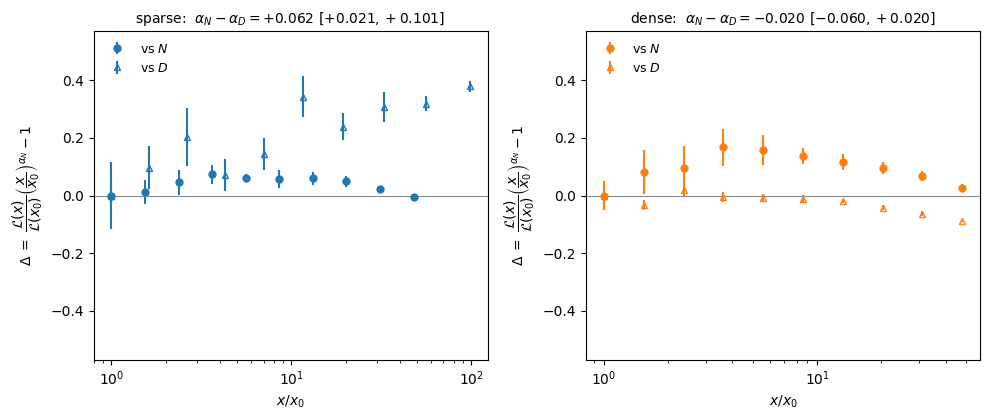

     arm  alpha_N  alpha_D      gap                95% CI    P>0  Delta at top
  sparse    1.321    1.259   +0.062  [+0.021, +0.101]  0.998        +32.8%
   dense    1.242    1.262   -0.020  [-0.060, +0.020]  0.174         -7.5%


In [8]:
require(6)

COL, MK = {"sparse": "C0", "dense": "C1"}, {"N": "o", "D": "^"}
getx = lambda arm, v: xN[arm] if v == "N" else xD[arm]
alph = lambda arm, v: (aN[arm] if v == "N" else aD[arm])

print("\nFigure 1.  Loss against each resource; each sweep fitted independently.\n")
fig1, ax1 = plt.subplots(2, 2, figsize=(9.6, 7.2))
for i, arm in enumerate(("sparse", "dense")):
    for j, v in enumerate(("N", "D")):
        A, x, Y = ax1[i, j], getx(arm, v), R[(arm, v)]
        a, b = alph(arm, v)
        m, e = gmean(Y), gse(Y)
        A.errorbar(x, m, e, fmt=MK[v], color=COL[arm], mfc=COL[arm] if v == "N" else "none",
                   ms=5, label=f"{arm}, {Y.shape[0]} seeds")
        xs = np.array([x[0], x[-1]])
        c0 = np.log(m).mean() + a * np.log(x).mean()
        A.plot(xs, np.exp(c0 - a * np.log(xs)), "k--", lw=1.0, zorder=0)
        A.set(xscale="log", yscale="log", xlabel=f"${v}$", ylabel=r"$\mathcal{L}$")
        A.legend(frameon=False, fontsize=8, loc="lower left")
        A.set_title(rf"{arm}, ${v}$-sweep:  "
                    rf"$\alpha_{v}={a:.3f}\,[{np.percentile(b,2.5):.3f},{np.percentile(b,97.5):.3f}]$",
                    fontsize=10)
fig1.tight_layout()
try:    fig1.savefig(f"{CKPT}/fig_sweeps.pdf", bbox_inches="tight")
except Exception: fig1.savefig("fig_sweeps.pdf", bbox_inches="tight")
plt.show()

print("\n\nFigure 2.  Each arm compensated by its own model-size exponent.\n"
      "Delta = 0 means the sweep follows the same power law as that arm's N-sweep;\n"
      "the residual slope of the D-sweep is exactly alpha_N - alpha_D.\n")
fig2, ax2 = plt.subplots(1, 2, figsize=(10.0, 4.3))
lim = 0.0
for A, arm in zip(ax2, ("sparse", "dense")):
    a_n = aN[arm][0]; gap = a_n - aD[arm][0]; bgap = aN[arm][1] - aD[arm][1]
    for v in ("N", "D"):
        x, Y = getx(arm, v), R[(arm, v)]
        m, e = gmean(Y), gse(Y)
        d  = (x / x[0]) ** a_n * m / m[0] - 1
        de = (x / x[0]) ** a_n * e / m[0]
        A.errorbar(x / x[0], d, de, fmt=MK[v], color=COL[arm],
                   mfc=COL[arm] if v == "N" else "none", ms=5, label=f"vs ${v}$")
        lim = max(lim, np.abs(d).max() + np.abs(de).max())
    A.axhline(0.0, color="0.55", lw=0.8)
    A.set(xscale="log", xlabel=r"$x/x_0$")
    A.set_ylabel(r"$\Delta \;=\; \dfrac{\mathcal{L}(x)}{\mathcal{L}(x_0)}"
                 r"\left(\dfrac{x}{x_0}\right)^{\alpha_N}-1$", fontsize=10)
    A.legend(frameon=False, fontsize=9, loc="upper left")
    A.set_title(rf"{arm}:  $\alpha_N-\alpha_D={gap:+.3f}$ "
                rf"$[{np.percentile(bgap,2.5):+.3f},{np.percentile(bgap,97.5):+.3f}]$", fontsize=10)
for A in ax2:
    A.set_ylim(-1.15 * lim, 1.15 * lim)
fig2.tight_layout()
try:    fig2.savefig(f"{CKPT}/fig_compensated.pdf", bbox_inches="tight")
except Exception: fig2.savefig("fig_compensated.pdf", bbox_inches="tight")
plt.show()

print(f"{'arm':>8}{'alpha_N':>9}{'alpha_D':>9}{'gap':>9}{'95% CI':>22}{'P>0':>7}{'Delta at top':>14}")
for arm in ("sparse", "dense"):
    a_n, b_n = aN[arm]; a_d, b_d = aD[arm]; g, bg = a_n - a_d, b_n - b_d
    dec = np.log10(getx(arm, "D")[-1] / getx(arm, "D")[0])
    print(f"{arm:>8}{a_n:9.3f}{a_d:9.3f}{g:+9.3f}"
          f"  [{np.percentile(bg,2.5):+.3f}, {np.percentile(bg,97.5):+.3f}]"
          f"{(bg>0).mean():7.3f}{100*(10**(g*dec)-1):+13.1f}%")
done(7)

## Appendix

In [9]:
require(6)

# A1. The sparse D-curve, predicted with nothing fitted: the loss should equal the
# variance carried by coordinates that were never observed.
pred = np.array([[var[rng_for(34, s*1000 + int(D)).multinomial(int(D), p) == 0].sum()
                  for D in D_SPARSE] for s in range(R[("sparse","D")].shape[0])])
rat  = R[("sparse","D")] / pred
print(f"A1  measured / predicted, sparse D-sweep")
print(f"{'D':>8}{'predicted':>12}{'measured':>12}{'ratio':>8}")
for i, D in enumerate(D_SPARSE):
    print(f"{D:8d}{gmean(pred)[i]:12.3e}{gmean(R[('sparse','D')])[i]:12.3e}{gmean(rat)[i]:8.3f}")
print(f"    mean ratio {gmean(rat).mean():.3f}; excess is min-norm leakage onto "
      f"unobserved coordinates, of order K/N = {K_sp.max()/N_FIXED:.3f}\n")

# A2. Is the resource min(N, K)? Replot the D-sweep against effective rank.
print("A2  alpha_N vs alpha_K at matched effective rank")
for a, xk in (("sparse", K_sp), ("dense", D_DENSE.astype(float))):
    k, bk = slope(xk, R[(a, "D")])
    n, bn = aN[a]
    print(f"    {a:7} alpha_N {n:.3f}   alpha_K {k:.3f}   diff {n-k:+.3f} {ci(bn-bk)}")
print("    Coverage selects a random subset of coordinates while capacity")
print("    captures approximately the top directions, so a coverage-")
print("    selected coordinate contributes less than a random feature.")

# A3. Is the gap driven by drift, or by the ends of the window? Refit on sub-windows.
def gap_on(mN, mD, nboot=4000):
    n,  bn  = slope(xN["sparse"][mN], R[("sparse","N")][:, mN], nboot)
    d,  bd  = slope(xD["sparse"][mD], R[("sparse","D")][:, mD], nboot)
    nd, bnd = slope(xN["dense"][mN],  R[("dense","N")][:, mN],  nboot)
    dd_, bdd = slope(xD["dense"][mD], R[("dense","D")][:, mD],  nboot)
    return (n - d, bn - bd), ((n - d) - (nd - dd_), (bn - bd) - (bnd - bdd))

full = np.ones(len(N_LADDER), bool)
cut  = lambda i: np.array([j != (i % len(full)) for j in range(len(full))])
half = lambda hi: (np.arange(len(full)) >= len(full)//2) if hi else (np.arange(len(full)) < (len(full)+1)//2)
wins = [("full window", full, full), ("drop lowest", cut(0), cut(0)),
        ("drop highest", cut(-1), cut(-1)), ("upper half", half(True), half(True)),
        ("lower half", half(False), half(False))]

print("\nA3  sub-window stability of the sparse gap")
print(f"{'window':>14}{'pts':>5}{'sparse gap':>24}{'minus dense':>24}")
for lab, mN, mD in wins:
    (g, bg), (dd_, bdd) = gap_on(mN, mD)
    print(f"{lab:>14}{mN.sum():5d}{g:8.3f} {ci(bg)}{dd_:8.3f} {ci(bdd)}")
print("    Drift within the window would show as the gap moving with the window.")
done(8)

A1  measured / predicted, sparse D-sweep
       D   predicted    measured   ratio
     103   4.283e-03   3.683e-03   0.860
     166   2.261e-03   2.150e-03   0.951
     271   1.372e-03   1.235e-03   0.900
     441   6.510e-04   5.779e-04   0.888
     721   3.418e-04   3.227e-04   0.944
    1193   1.838e-04   1.946e-04   1.059
    1995   9.117e-05   9.102e-05   0.998
    3373   4.703e-05   4.804e-05   1.022
    5765   2.272e-05   2.384e-05   1.049
   10073   1.076e-05   1.194e-05   1.109
    mean ratio 0.978; excess is min-norm leakage onto unobserved coordinates, of order K/N = 0.096

A2  alpha_N vs alpha_K at matched effective rank
    sparse  alpha_N 1.321   alpha_K 1.485   diff -0.165 [-0.211, -0.121]
    dense   alpha_N 1.242   alpha_K 1.262   diff -0.020 [-0.060, +0.020]
    Coverage selects a random subset of coordinates while capacity
    captures approximately the top directions, so a coverage-
    selected coordinate contributes less than a random feature.

A3  sub-window stab